# Bibliotecas y figuras

**Responsable:** Isabela Quintero Murillo

**Objetivo:** consultas 10 y 11 (bibliotecas `.fasta` parametrizadas) y las 4 figuras obligatorias, a partir de consultas a MongoDB.

Modelo de referencia: `../MODELO.md`. Base: `panteon` restaurada del dump (`resultados/dump_info.md`).

**Antes de subir:** *Kernel → Restart & Run All* para comprobar que todo corre desde cero. Las salidas **se conservan**: el enunciado pide presentar el resultado de cada consulta, y el artículo remite a estos notebooks para ver el código y el resultado de cada una.

In [1]:
from pathlib import Path
import gzip
import shutil

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pymongo import MongoClient

client = MongoClient("mongodb://localhost:27017")
db = client["panteon"]

CARPETA_BIBLIOTECAS = Path("../bibliotecas")
CARPETA_FIGURAS = Path("../figuras")
CARPETA_BIBLIOTECAS.mkdir(exist_ok=True)
CARPETA_FIGURAS.mkdir(exist_ok=True)

# Estilo común de las figuras: fondo blanco y letra pequeña, como pide la revista
sns.set_theme(style="whitegrid", context="paper", font_scale=0.9)
ANCHO_1COL = 3.4   # pulgadas (86 mm)
ANCHO_2COL = 7.0   # pulgadas (178 mm)
COLOR_REINO = {"Animalia": "#0072B2", "Plantae": "#009E73", "Fungi": "#D55E00"}


def guardar_figura(fig, nombre):
    ruta = CARPETA_FIGURAS / nombre
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
    print("Guardada:", ruta)

### Verificación rápida de la base

Antes de empezar se comprueba que la base está completa, contando los documentos de cada colección con `count_documents({})`. Valores esperados (`resultados/dump_info.md`): `especies` 2.790, `tes` 239.946, `secuencias` 239.946, `kmers` 1.439.676.

In [2]:
esperado = {"especies": 2790, "tes": 239946, "secuencias": 239946, "kmers": 1439676}

for coleccion, valor in esperado.items():
    real = db[coleccion].count_documents({})
    print(f"{coleccion:<11} {real:>9,}  {'OK' if real == valor else 'DIFERENTE'}")

especies        2,790  OK
tes           239,946  OK


secuencias    239,946  OK


kmers       1,439,676  OK


## Bibliotecas

Una biblioteca es el conjunto de secuencias de un grupo, exportado a `.fasta` con el mismo encabezado del archivo original:

```
>ID#CLASE/ORDEN/SUPERFAMILIA @Especie
SECUENCIA
```

Correspondencia con el modelo:

| Parte del encabezado | Campo en la base |
| --- | --- |
| `ID` | `tes.pdb_id` |
| `CLASE/ORDEN/SUPERFAMILIA` | `tes.classification.te_class`, `te_order`, `te_superfamily` |
| `Especie` | `tes.species_name` (así queda igual al original) |
| secuencia | `secuencias.sequence`, buscando por el **mismo `_id`** del TE |

Reglas del enunciado:
- Construirla con una **consulta a la base**, no leyendo el FASTA original.
- La especie y el reino son **parámetros**: la misma función sirve para cualquier especie o reino.
- La secuencia se escribe **sin modificarla** (conserva minúsculas y N).

### Función común: escribir un `.fasta` a partir de un filtro

Las consultas 10 y 11 solo cambian el filtro (`{"species_name": ...}` o `{"kingdom": ...}`), así que una sola función recibe el filtro y el nombre del archivo.

Pasos:
1. Buscar en `tes` los documentos que cumplen el filtro, trayendo solo los campos del encabezado (proyección).
2. Traer las secuencias de esos TEs desde `secuencias` por lotes de 5.000 `_id`, con `secuencias.find({"_id": {"$in": lote}})`. Cada lote es una sola consulta que usa el índice de `_id`. La otra opción considerada era un `$lookup` de `tes` a `secuencias` dentro de una agregación, que busca la secuencia de cada TE por separado.
3. Escribir cada registro con el formato del encabezado: una línea de encabezado y una de secuencia.
4. Devolver cuántas secuencias se escribieron, para comprobarlo.

**Tamaño:** GitHub rechaza archivos de más de 100 MB. Si una biblioteca supera ese tamaño, la función la comprime con gzip y la guarda como `.fasta.gz`.

**Comprobación:** el número de secuencias escritas debe ser igual a `db.tes.count_documents(filtro)`.

In [3]:
LIMITE_GITHUB = 100 * 1024 * 1024  # 100 MB en bytes
TAM_LOTE = 5000                      # cuántos TEs se piden juntos a `secuencias`


def encabezado(te):
    """Arma la línea >ID#CLASE/ORDEN/SUPERFAMILIA @Especie de un documento de `tes`."""
    c = te["classification"]
    return f">{te['pdb_id']}#{c['te_class']}/{c['te_order']}/{c['te_superfamily']} @{te['species_name']}"


def escribir_lote(archivo, lote):
    """Trae de una vez las secuencias de un lote de TEs y escribe sus registros."""
    ids = [te["_id"] for te in lote]
    secuencias = {s["_id"]: s["sequence"] for s in db.secuencias.find({"_id": {"$in": ids}})}
    for te in lote:
        archivo.write(encabezado(te) + "\n" + secuencias[te["_id"]] + "\n")
    return len(lote)


def escribir_biblioteca(filtro, nombre):
    """Escribe en bibliotecas/ el .fasta de los TEs que cumplen `filtro`.

    Si el archivo pasa de 100 MB lo comprime a .fasta.gz (límite de GitHub).
    Devuelve la ruta final y cuántas secuencias escribió.
    """
    ruta = CARPETA_BIBLIOTECAS / f"{nombre}.fasta"
    proyeccion = {"pdb_id": 1, "species_name": 1, "classification": 1}  # solo lo del encabezado

    escritas = 0
    with open(ruta, "w") as archivo:
        lote = []
        for te in db.tes.find(filtro, proyeccion).sort("_id", 1):
            lote.append(te)
            if len(lote) == TAM_LOTE:
                escritas += escribir_lote(archivo, lote)
                lote = []
        if lote:
            escritas += escribir_lote(archivo, lote)

    if ruta.stat().st_size > LIMITE_GITHUB:
        ruta_gz = ruta.with_suffix(".fasta.gz")
        with open(ruta, "rb") as origen, gzip.open(ruta_gz, "wb") as destino:
            shutil.copyfileobj(origen, destino)
        ruta.unlink()
        ruta = ruta_gz

    return ruta, escritas


def resumen_biblioteca(filtro, ruta, escritas):
    """Comprueba el conteo, muestra tamaño, órdenes y las primeras líneas del archivo."""
    esperadas = db.tes.count_documents(filtro)
    print(f"Archivo: {ruta}")
    print(f"Secuencias escritas: {escritas:,} (esperadas: {esperadas:,}) -> {'OK' if escritas == esperadas else 'ERROR'}")
    print(f"Tamaño: {ruta.stat().st_size / 1024 / 1024:.2f} MB")
    ordenes = db.tes.aggregate([
        {"$match": filtro},
        {"$group": {"_id": "$classification.te_order", "n": {"$sum": 1}}},
        {"$sort": {"n": -1}},
    ])
    print("TEs por orden:", {d["_id"]: d["n"] for d in ordenes})
    abrir = gzip.open if ruta.suffix == ".gz" else open
    with abrir(ruta, "rt") as archivo:
        print("Primeras líneas:")
        for _, linea in zip(range(4), archivo):
            print("  " + (linea.rstrip()[:80] + "..." if len(linea) > 80 else linea.rstrip()))

### Consulta 10: biblioteca de una especie

**Pregunta:** ¿cuál es la biblioteca de TEs de una especie dada?

Parámetro: `ESPECIE`, con el nombre tal como está en `tes.species_name`. Como ejemplo se usa una especie pequeña, la del primer TE del FASTA: *Halicephalobus mephisto*.

**Nombres con punto:** en 4 especies el nombre del FASTA tiene punto (`subsp.`, `sp.`) y el del CSV no (ver `resultados/reporte_cruce.md`). Como el filtro es por `species_name`, hay que usar el nombre como aparece en la base, que es el del FASTA. Antes de escribir el archivo, la celda comprueba que el filtro encuentre al menos un TE; si no encuentra ninguno, se detiene con un `ValueError` en lugar de generar una biblioteca vacía.

In [4]:
ESPECIE = "Halicephalobus mephisto"  # parámetro

filtro_especie = {"species_name": ESPECIE}
if db.tes.count_documents(filtro_especie) == 0:
    raise ValueError("No hay TEs con ese nombre; usa el nombre exacto de tes.species_name, por ejemplo con punto en subsp./sp.")
nombre_archivo = "especie_" + ESPECIE.replace(" ", "_").replace(".", "")
ruta, escritas = escribir_biblioteca(filtro_especie, nombre_archivo)
resumen_biblioteca(filtro_especie, ruta, escritas)

Archivo: ../bibliotecas/especie_Halicephalobus_mephisto.fasta
Secuencias escritas: 10 (esperadas: 10) -> OK
Tamaño: 0.02 MB
TEs por orden: {'TIR': 7, 'HELITRON': 2, 'LINE': 1}
Primeras líneas:
  >PDB00000001#CLASSII/HELITRON/HELITRON @Halicephalobus mephisto
  aaaaaacaaaagaacttaaattttttaaaatttcaatataaaaaaaattttaaatttttttttaaatcaaaaattattaa...
  >PDB00000002#CLASSII/HELITRON/HELITRON @Halicephalobus mephisto
  tttaaataataaatttttatttttaaaattataaaattaatttttaaaaatttcaaaaaaaaaaaataaatttttttata...


**Resultado e interpretación (consulta 10):** la biblioteca de *Halicephalobus mephisto* tiene **10 secuencias** (7 TIR, 2 HELITRON y 1 LINE) y ocupa 17 KB. El número de secuencias escritas coincide con `count_documents` sobre el mismo filtro, y las primeras líneas muestran el encabezado original `>ID#CLASE/ORDEN/SUPERFAMILIA @Especie` con la secuencia sin modificar (en minúsculas, como en el FASTA de PanTEon). Para otra especie basta cambiar `ESPECIE`.

### Consulta 11: biblioteca de un reino

**Pregunta:** ¿cuál es la biblioteca de TEs de un reino dado?

Parámetro: `REINO` (Animalia, Plantae o Fungi), filtrando por `tes.kingdom`, que tiene índice.

In [5]:
REINO = "Fungi"  # parámetro: Animalia, Plantae o Fungi

filtro_reino = {"kingdom": REINO}
ruta, escritas = escribir_biblioteca(filtro_reino, "reino_" + REINO)
resumen_biblioteca(filtro_reino, ruta, escritas)

Archivo: ../bibliotecas/reino_Fungi.fasta
Secuencias escritas: 19,797 (esperadas: 19,797) -> OK
Tamaño: 69.77 MB
TEs por orden: {'LTR': 7937, 'LINE': 6137, 'TIR': 3063, 'HELITRON': 1695, 'DIRS': 762, 'MITE': 97, 'SINE': 91, 'MAVERICK': 15}
Primeras líneas:
  >PDB00054620#CLASSII/TIR/PIFHARBINGER @Circinella umbellata
  gaccatccgcagcggtggttgttacaaattgttaaattaccccaattaacagtccgcgtaacaacatctaacaatcaaat...
  >PDB00054621#CLASSII/TIR/PIFHARBINGER @Circinella umbellata
  acttttatttgctatacctttatatctaagaccagccgcagcggtgctgttacaaaattgttatgttacatgtaattaac...


**Resultado e interpretación (consulta 11):** la biblioteca de Fungi tiene **19.797 secuencias** y ocupa **69,8 MB**. Como está por debajo de 100 MB, no hubo que comprimirla. Por orden: LTR 7.937, LINE 6.137, TIR 3.063, HELITRON 1.695, DIRS 762, MITE 97, SINE 91 y MAVERICK 15. Las bibliotecas de Animalia (101.144 TEs) y Plantae (119.005) pasarían de 100 MB, así que la función las guardaría como `.fasta.gz`.

**En el repositorio:** las dos bibliotecas (`bibliotecas/especie_Halicephalobus_mephisto.fasta` y `bibliotecas/reino_Fungi.fasta`) se suben al repositorio y no van en `.gitignore`, porque el entregable 6 del enunciado pide al menos una biblioteca por especie y una por reino. La de Fungi (69,8 MB) está por debajo del límite de 100 MB de GitHub.

## Figuras

Todas con datos leídos desde MongoDB (resultado de una consulta), generadas con matplotlib o seaborn y guardadas en `figuras/` con estos nombres, que son los que espera `articulo/main.tex`. En el artículo son las Figuras 2 a 5, porque la Figura 1 es el diagrama del modelo:

| Figura | Archivo |
| --- | --- |
| 1. Composición de TEs por reino | `figuras/fig1_composicion_reino.png` |
| 2. Longitud por orden | `figuras/fig2_longitud_orden.png` |
| 3. GC por reino | `figuras/fig3_gc_reino.png` |
| 4. Heatmap de 2-mers | `figuras/fig4_heatmap_2mers.png` |

Normas de la revista (ver `JOURNAL.md`): fondo blanco, ancho de una columna (86 mm, unos 3,4 pulgadas) o de dos (178 mm, unos 7 pulgadas), sin capturas de pantalla. Por eso se usa un ancho de 3,4 o 7 pulgadas (`ANCHO_1COL` y `ANCHO_2COL`) y se guarda con `savefig(..., dpi=300, bbox_inches="tight", facecolor="white")` (función `guardar_figura`).

En el artículo, cada figura lleva su interpretación y un **texto alternativo** que la describe.

### Figura 1: composición de TEs por reino

**Qué pide el enunciado:** gráfico de barras con la cantidad (o el porcentaje) de TEs de cada orden en Animalia, Plantae y Fungi.

**Consulta:** una agregación en `tes` que agrupa por `kingdom` y `classification.te_order` y cuenta (`$group` con `$sum: 1`). El resultado se pasa a un DataFrame y se pivota (reino × orden).

**Decisión:** se usa el porcentaje dentro de cada reino. Como Fungi tiene muchos menos TEs (19.797) que Plantae (119.005), el porcentaje permite comparar la composición; la cantidad mostraría sobre todo el tamaño de cada reino.

TEs por reino: {'Animalia': 101144, 'Fungi': 19797, 'Plantae': 119005}


reino,Animalia,Plantae,Fungi
orden,,,
LTR,25.1,72.3,40.1
LINE,44.0,14.9,31.0
TIR,21.4,9.9,15.5
HELITRON,1.2,1.9,8.6
SINE,3.1,0.4,0.5
MITE,2.7,0.5,0.5
DIRS,2.1,0.0,3.8
PLE,0.3,0.1,0.0
RETROPOSON,0.1,0.0,0.0


Guardada: ../figuras/fig1_composicion_reino.png


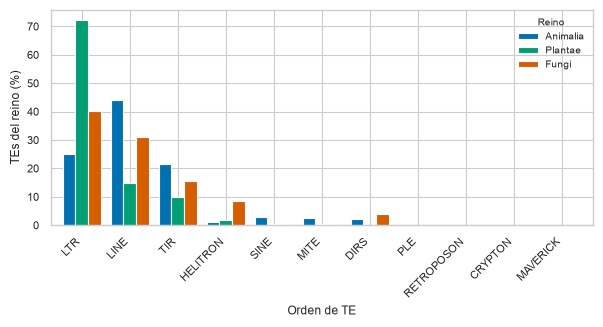

In [6]:
conteo = pd.DataFrame(
    [{"reino": d["_id"]["reino"], "orden": d["_id"]["orden"], "n": d["n"]}
     for d in db.tes.aggregate([
         {"$group": {"_id": {"reino": "$kingdom", "orden": "$classification.te_order"}, "n": {"$sum": 1}}},
     ])]
)
tabla = conteo.pivot(index="orden", columns="reino", values="n").fillna(0)
porcentaje = tabla / tabla.sum() * 100           # porcentaje dentro de cada reino
porcentaje = porcentaje.loc[tabla.sum(axis=1).sort_values(ascending=False).index]
porcentaje = porcentaje[["Animalia", "Plantae", "Fungi"]]

print("TEs por reino:", tabla.sum().astype(int).to_dict())
display(porcentaje.round(1))

fig, ax = plt.subplots(figsize=(ANCHO_2COL, 2.8))
porcentaje.plot.bar(ax=ax, width=0.8, color=[COLOR_REINO[r] for r in porcentaje.columns], edgecolor="white")
ax.set_xlabel("Orden de TE")
ax.set_ylabel("TEs del reino (%)")
ax.legend(title="Reino", frameon=False, fontsize=7, title_fontsize=7)
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
guardar_figura(fig, "fig1_composicion_reino.png")
plt.show()

**Interpretación (figura 1):** se usa el porcentaje dentro de cada reino porque Fungi tiene seis veces menos TEs que Plantae. En **Plantae** dominan los LTR (72,3 %). En **Animalia** el orden más frecuente es LINE (44,0 %), seguido de LTR (25,1 %) y TIR (21,4 %). **Fungi** queda en un punto intermedio, con LTR (40,1 %) y LINE (31,0 %), y es el reino con más HELITRON (8,6 %) y DIRS (3,8 %). SINE y MITE solo superan el 1 % en Animalia, y PLE, RETROPOSON, CRYPTON y MAVERICK no llegan al 0,5 % en ningún reino.

### Figura 2: longitud de los TEs por orden

**Qué pide el enunciado:** diagrama de cajas (boxplot) de la longitud por orden de TE.

**Consulta:** se traen de `tes` solo `classification.te_order` y `length` (proyección, sin `_id`). Son 239.946 documentos pequeños, que caben en memoria sin problema.

**Decisiones:** como las longitudes van de 81 a 19.926 nt, se usa escala logarítmica, y los órdenes se ordenan por su mediana para facilitar la lectura.

Las medianas se calculan con pandas (exactas); el notebook 04 usa `$median` aproximado de MongoDB, por eso pueden diferir un poco (por ejemplo, MAVERICK).

,count,min,mediana,max
orden,,,,
SINE,3634,81,254,500
CRYPTON,112,108,282,2367
MITE,3456,100,345,500
RETROPOSON,113,195,1159,3463
TIR,36471,100,1341,9991
PLE,344,107,2208,8809
LINE,68382,500,3279,6000
HELITRON,5075,100,3371,14819
DIRS,2933,109,5143,6998


Guardada: ../figuras/fig2_longitud_orden.png


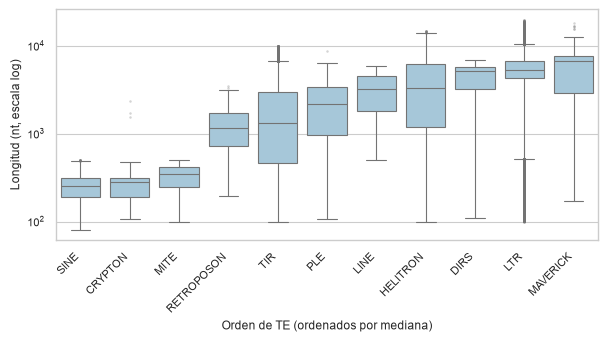

In [7]:
longitudes = pd.DataFrame(db.tes.find({}, {"_id": 0, "orden": "$classification.te_order", "length": 1}))
orden_por_mediana = longitudes.groupby("orden")["length"].median().sort_values().index

display(longitudes.groupby("orden")["length"].describe()[["count", "min", "50%", "max"]]
        .loc[orden_por_mediana].astype(int).rename(columns={"50%": "mediana"}))

fig, ax = plt.subplots(figsize=(ANCHO_2COL, 3.0))
sns.boxplot(data=longitudes, x="orden", y="length", order=orden_por_mediana, ax=ax,
            color="#9ecae1", linewidth=0.8, fliersize=0.8, flierprops={"alpha": 0.3})
ax.set_yscale("log")
ax.set_xlabel("Orden de TE (ordenados por mediana)")
ax.set_ylabel("Longitud (nt, escala log)")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
guardar_figura(fig, "fig2_longitud_orden.png")
plt.show()

**Interpretación (figura 2):** hay dos grupos. **SINE, CRYPTON y MITE** son cortos, con medianas entre 254 y 345 nt. **LTR, DIRS y MAVERICK** son los más largos, con medianas por encima de 5.000 nt, y en LTR está el TE más largo de la base (19.926 nt). HELITRON y TIR tienen la mayor dispersión (de 100 a 14.819 y a 9.991 nt). SINE y MITE nunca pasan de 500 nt y LINE nunca baja de esa cifra: parecen cortes de los criterios de la biblioteca de origen, lo que queda por verificar en la documentación de PanTEon. Se usa escala logarítmica porque las longitudes van de 81 a 19.926 nt.

### Figura 3: contenido GC por reino

**Qué pide el enunciado:** comparación del porcentaje de GC entre reinos (barras o boxplot).

**Consulta:** se traen de `tes` los campos `kingdom` y `gc_content`. Según `MODELO.md`, `gc_content` está guardado como fracción (de 0 a 1), así que se multiplica por 100 para rotular el eje en porcentaje.

El GC se calculó excluyendo las N del denominador (`MODELO.md`), así que no hace falta corregirlo.

,count,media,mediana,std
kingdom,,,,
Animalia,101144.0,44.63,44.09,8.07
Plantae,119005.0,41.43,40.95,6.45
Fungi,19797.0,46.47,47.06,8.97


Guardada: ../figuras/fig3_gc_reino.png


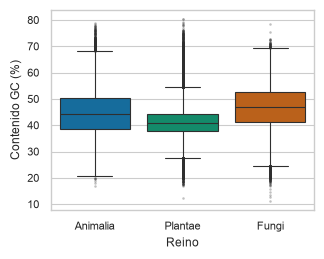

In [8]:
gc = pd.DataFrame(db.tes.find({}, {"_id": 0, "kingdom": 1, "gc_content": 1}))
gc["gc_pct"] = gc["gc_content"] * 100   # en la base está como fracción (0 a 1)
reinos = ["Animalia", "Plantae", "Fungi"]

display(gc.groupby("kingdom")["gc_pct"].describe()[["count", "mean", "50%", "std"]]
        .loc[reinos].round(2).rename(columns={"50%": "mediana", "mean": "media"}))

fig, ax = plt.subplots(figsize=(ANCHO_1COL, 2.6))
sns.boxplot(data=gc, x="kingdom", y="gc_pct", order=reinos, hue="kingdom", palette=COLOR_REINO,
            legend=False, ax=ax, linewidth=0.8, fliersize=0.8, flierprops={"alpha": 0.3})
ax.set_xlabel("Reino")
ax.set_ylabel("Contenido GC (%)")
guardar_figura(fig, "fig3_gc_reino.png")
plt.show()

**Interpretación (figura 3):** `gc_content` está como fracción en la base y se multiplicó por 100. **Fungi** tiene el GC más alto (mediana 47,1 %), luego **Animalia** (44,1 %) y **Plantae** (41,0 %). Las distribuciones se solapan mucho, así que la diferencia es de tendencia, no una separación. Plantae tiene la menor dispersión (desviación estándar de 6,5 puntos, frente a 8,1 en Animalia y 9,0 en Fungi).

### Figura 4: heatmap de 2-mers por orden

**Qué pide el enunciado:** frecuencia promedio de los 16 2-mers (AA, AC, …, TT) por orden de TE. ¿Hay órdenes con perfiles parecidos o muy distintos?

**Consulta:** se reutiliza la agregación **Q2, versión `"coleccion"`** de `06_benchmark_consultas.ipynb` (función `pipeline_q2` y `PIPELINE_Q2["coleccion"]`), que ya está verificada. Se aplica a `db.kmers` con el filtro `{"k": 2}` (usa el índice `{k, te_order}`).

**Ojo al promediar:** en `counts` solo aparecen los k-mers presentes. La frecuencia por TE es `counts / valid_windows`, y el promedio por orden es **la suma de frecuencias dividida por el número total de TEs del orden**. No usar `$avg` después de `$unwind`, porque ignora los TEs donde ese 2-mer vale 0. La Q2 ya lo hace bien.

**Tiempo:** en el benchmark de consultas, esta agregación tardó 11,7 ± 7,1 s (Q2, colección `kmers` con índice; `resultados/benchmark_consultas.csv`).

El resultado se pivota a una tabla orden × 2-mer y se dibuja con `seaborn.clustermap`, que agrupa los órdenes con perfiles parecidos (dendrograma) y así ayuda a responder la pregunta del enunciado.

kmer,AA,AC,AG,AT,CA,CC,CG,CT,GA,GC,GG,GT,TA,TC,TG,TT
te_order,,,,,,,,,,,,,,,,
CRYPTON,0.089,0.049,0.064,0.084,0.061,0.060,0.056,0.037,0.064,0.063,0.068,0.049,0.072,0.042,0.057,0.086
DIRS,0.059,0.057,0.062,0.052,0.071,0.079,0.056,0.071,0.061,0.067,0.072,0.052,0.039,0.075,0.061,0.067
HELITRON,0.097,0.053,0.058,0.089,0.067,0.045,0.036,0.055,0.064,0.046,0.048,0.051,0.067,0.059,0.068,0.096
LINE,0.095,0.054,0.068,0.073,0.066,0.051,0.030,0.064,0.070,0.046,0.063,0.051,0.058,0.060,0.069,0.082
LTR,0.091,0.051,0.067,0.077,0.064,0.050,0.030,0.063,0.069,0.044,0.054,0.054,0.061,0.063,0.071,0.092
MAVERICK,0.100,0.057,0.054,0.089,0.063,0.037,0.048,0.053,0.063,0.045,0.038,0.056,0.072,0.063,0.063,0.099
MITE,0.104,0.054,0.054,0.079,0.063,0.053,0.035,0.053,0.053,0.044,0.057,0.057,0.071,0.053,0.065,0.104
PLE,0.095,0.061,0.053,0.072,0.064,0.060,0.051,0.061,0.053,0.057,0.050,0.052,0.068,0.058,0.058,0.085
RETROPOSON,0.081,0.052,0.062,0.054,0.060,0.081,0.040,0.072,0.064,0.061,0.082,0.048,0.045,0.058,0.072,0.068


Guardada: ../figuras/fig4_heatmap_2mers.png


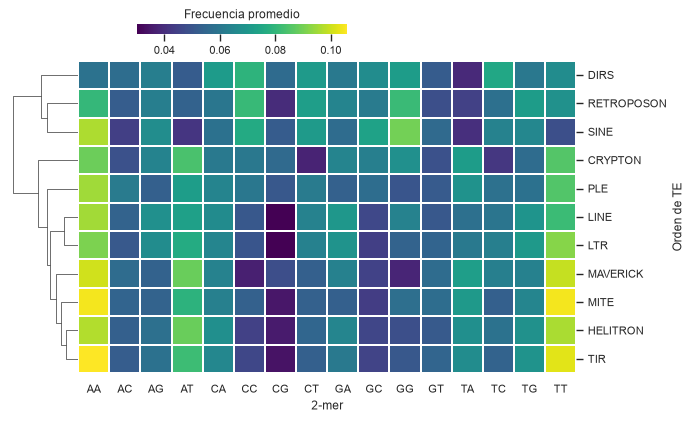

In [9]:
# Q2, versión "coleccion", copiada de 06_benchmark_consultas.ipynb
def pipeline_q2(filtro, orden, counts, ventanas):
    return [
        {"$match": filtro},
        {"$project": {"_id": 0, "te_order": orden, "f": {"$map": {
            "input": {"$objectToArray": counts},
            "in": {"kmer": "$$this.k", "f": {"$divide": ["$$this.v", ventanas]}},
        }}}},
        {"$facet": {
            "n": [{"$group": {"_id": "$te_order", "n_tes": {"$sum": 1}}}],
            "suma": [{"$unwind": "$f"}, {"$group": {"_id": {"o": "$te_order", "kmer": "$f.kmer"}, "s": {"$sum": "$f.f"}}}],
        }},
        {"$unwind": "$suma"},
        {"$project": {
            "te_order": "$suma._id.o", "kmer": "$suma._id.kmer",
            "frecuencia": {"$divide": ["$suma.s", {"$first": {"$map": {
                "input": {"$filter": {"input": "$n", "cond": {"$eq": ["$$this._id", "$suma._id.o"]}}},
                "in": "$$this.n_tes",
            }}}]},
        }},
    ]


filas = list(db.kmers.aggregate(pipeline_q2({"k": 2}, "$te_order", "$counts", "$valid_windows"), allowDiskUse=True))
perfil = (pd.DataFrame(filas).pivot(index="te_order", columns="kmer", values="frecuencia")
          .fillna(0.0).sort_index().sort_index(axis=1))
display(perfil.round(3))

grafico = sns.clustermap(perfil, cmap="viridis", figsize=(ANCHO_2COL, 4.2), col_cluster=False,
                         linewidths=0.3, dendrogram_ratio=(0.12, 0.12),
                         cbar_pos=(0.2, 0.93, 0.3, 0.025),
                         cbar_kws={"label": "Frecuencia promedio", "orientation": "horizontal"})
grafico.ax_cbar.xaxis.set_label_position("top")
grafico.ax_heatmap.set_xlabel("2-mer")
grafico.ax_heatmap.set_ylabel("Orden de TE")
guardar_figura(grafico.fig, "fig4_heatmap_2mers.png")
plt.show()

**Interpretación (figura 4):** CG es el 2-mer menos frecuente en seis de los 11 órdenes (LINE, LTR, TIR, MITE, HELITRON y RETROPOSON) y llega a su mínimo en LINE y LTR (0,030), lo que concuerda con el déficit de CpG conocido en genomas eucariotas. El dendrograma agrupa los órdenes así:
- **LINE y LTR**, con perfiles casi iguales.
- **TIR, MITE, HELITRON y MAVERICK**, ricos en AA y TT (0,096 a 0,106).
- **SINE, RETROPOSON y DIRS**, los más distintos: más CC y GG y menos AT, TA o TT.

CRYPTON (112 TEs), MAVERICK (58) y RETROPOSON (113) tienen pocos TEs, así que sus promedios son menos estables.